### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Getting dataset

In [2]:
df=pd.read_csv("../dataset/olist_order_reviews_dataset.csv")
df.head(2)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13


### Inferece
1) we have review_id assign to each order_id.
2) order_id to link tables.
3) review_score as rating.
4) review_comment_title	and review_comment_message as review.
5) review_creation_date date on which customer submitted the review.
6) review_answer_timestamp date when Olist or the seller responded to the review.

In [3]:
df.shape

(99224, 7)

In [4]:
df.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

### Insights 

In [6]:
# total reviews given
print(df['review_id'].nunique())

98410


In [7]:
## avg rating
df['review_score'].mean()

np.float64(4.08642062404257)

In [8]:
df['review_answer_timestamp']=pd.to_datetime(df['review_answer_timestamp'])
df['review_creation_date']=pd.to_datetime(df['review_creation_date'])

In [9]:
df['review_answer_timestamp']

0       2018-01-18 21:46:59
1       2018-03-11 03:05:13
2       2018-02-18 14:36:24
3       2017-04-21 22:02:06
4       2018-03-02 10:26:53
                ...        
99219   2018-07-14 17:18:30
99220   2017-12-11 20:06:42
99221   2018-03-23 09:10:43
99222   2018-07-02 12:59:13
99223   2017-07-03 21:01:49
Name: review_answer_timestamp, Length: 99224, dtype: datetime64[ns]

In [10]:
df['response_time']=df['review_answer_timestamp']-df['review_creation_date']

In [11]:
df['response_time']=df['response_time']
df['response_time'].value_counts()

response_time
1 days 00:44:33    7
0 days 23:22:05    6
0 days 23:36:35    6
0 days 23:05:28    6
0 days 23:08:09    6
                  ..
1 days 14:33:58    1
3 days 01:15:07    1
0 days 21:57:57    1
3 days 18:07:07    1
1 days 12:59:13    1
Name: count, Length: 82090, dtype: int64

In [12]:
df['response_time_days'] = df['response_time'].dt.days

In [13]:
# avg responce day/time
df['response_time'].mean().days

3

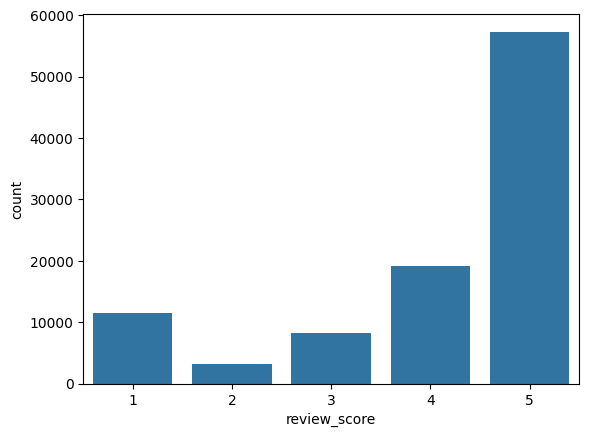

In [14]:
sns.countplot(x=df['review_score'])
plt.show()

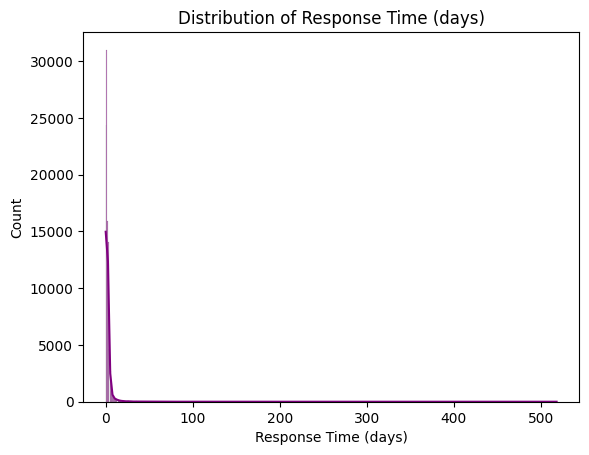

In [15]:
df['response_time_days'] = df['response_time'].dt.days

sns.histplot(data=df, x='response_time_days', kde=True, color='purple')
plt.title("Distribution of Response Time (days)")
plt.xlabel("Response Time (days)")
plt.ylabel("Count")
plt.show()

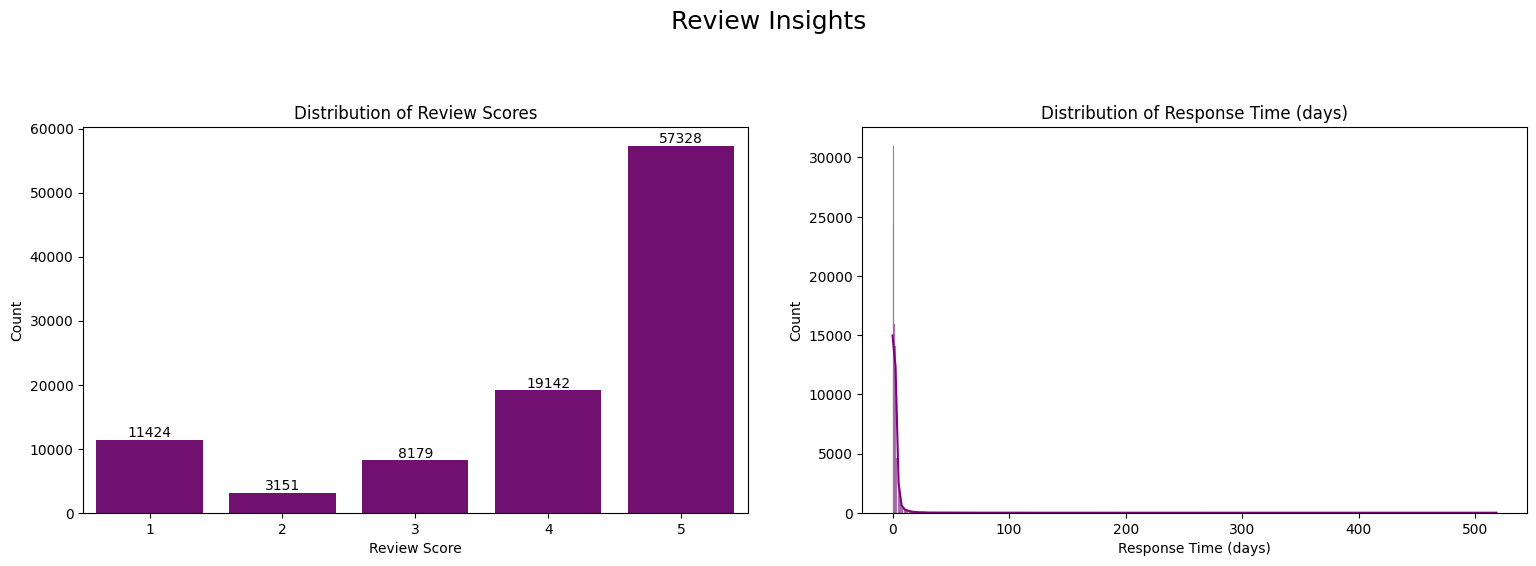

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.countplot(x='review_score', data=df, color='purple', ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Distribution of Review Scores")
axes[0].set_xlabel("Review Score")
axes[0].set_ylabel("Count")

sns.histplot(data=df, x='response_time_days', kde=True, color='purple', ax=axes[1])
axes[1].set_title("Distribution of Response Time (days)")
axes[1].set_xlabel("Response Time (days)")
axes[1].set_ylabel("Count")

plt.suptitle("Review Insights", fontsize=18)
plt.tight_layout(pad=3)
plt.savefig('Review_insights.png', dpi=500, bbox_inches="tight")
plt.show()

In [28]:
x1=df.groupby('review_score')['response_time_days'].mean().reset_index().sort_values(by='response_time_days',ascending=False)
x1.columns=['Rating','Response time']
x1

,Rating,Response time
4,5,2.640158
3,4,2.550047
0,1,2.501576
1,2,2.443669
2,3,2.417777


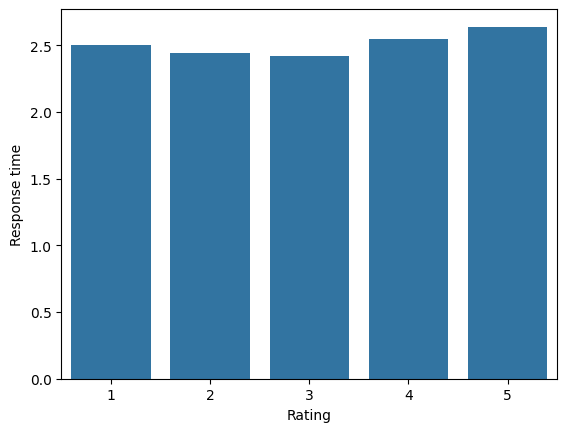

In [29]:
sns.barplot(data=x1,x='Rating',y='Response time')
plt.show()